In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms
from torchvision import datasets

import cv2
import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("OpenCV version:", cv2.__version__)

All libraries imported successfully!
PyTorch version: 2.14.0+cpu
Torchvision version: 0.29.0+cpu
OpenCV version: 4.10.0


In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

Selected device: cpu


In [3]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    transform=transform,
    download=True
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    transform=transform,
    download=True
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:14<00:00, 677kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 53.6kB/s]
100%|██████████| 1.65M/1.65M [00:03<00:00, 427kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.28MB/s]

Training images: 60000
Testing images: 10000


Image shape: torch.Size([1, 28, 28])
Correct label 5
Minimum pixel value: 0.0
Maximum pixel value: 1.0


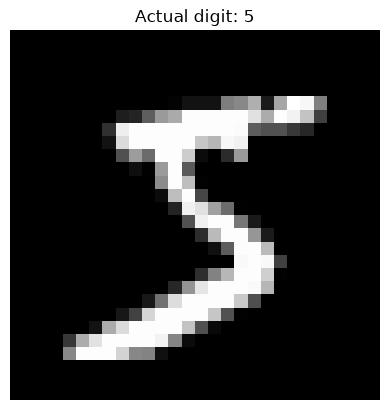

In [4]:
image,label=train_dataset[0]
print("Image shape:",image.shape)
print("Correct label",label)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())
plt.imshow(image.squeeze(0), cmap="gray")
plt.title(f"Actual digit: {label}")
plt.axis("off")
plt.show()

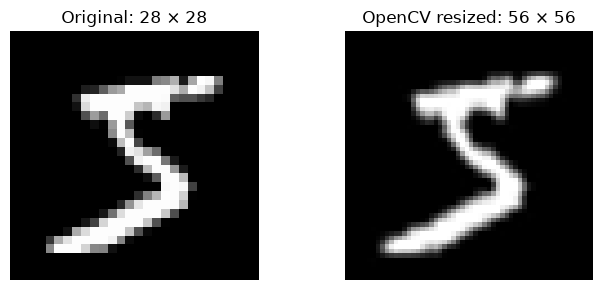

In [5]:
#convert the image into numpy array
image_array=image.squeeze(0).numpy()
# Convert normalized values back to the 0–255 pixel range
image_uint8=(image_array*255).astype(np.uint8)

# Resize using OpenCV
resized_image = cv2.resize(
    image_uint8,
    (56, 56),
    interpolation=cv2.INTER_CUBIC
)
plt.figure(figsize=(7, 3))

plt.subplot(1, 2, 1)
plt.imshow(image_uint8, cmap="gray")
plt.title("Original: 28 × 28")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_image, cmap="gray")
plt.title("OpenCV resized: 56 × 56")
plt.axis("off")

plt.tight_layout()
plt.show()

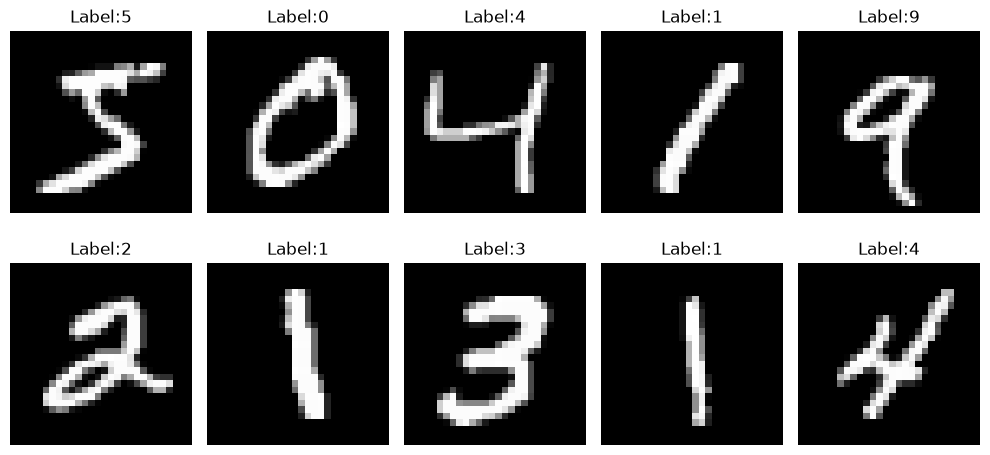

In [9]:
plt.figure(figsize=(10,5))

for i in range(10):
    image,label=train_dataset[i]

    plt.subplot(2,5,i+1)
    plt.imshow(image.squeeze(0),cmap="gray")
    plt.title(f"Label:{label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 938
Testing batches: 157


In [14]:
class DigitCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # First convolution: 1 input channel -> 16 feature maps
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        # Second convolution: 16 feature maps -> 32
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Activation and pooling
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Classification layers
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        # Block 1
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        # Block 2
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        # Classification head
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x


model = DigitCNN()

print(model)

DigitCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [15]:
images, labels = next(iter(train_loader))

print("Input batch shape:", images.shape)

with torch.no_grad():
    outputs = model(images)

print("Output shape:", outputs.shape)

Input batch shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [16]:
total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total trainable parameters:", total_params)

Total trainable parameters: 206922


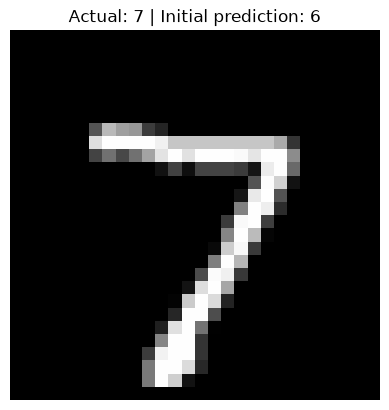

Actual digit: 7
Initial prediction: 6


In [17]:
import matplotlib.pyplot as plt

model.eval()

image, actual_label = test_dataset[0]

with torch.no_grad():
    logits = model(image.unsqueeze(0))
    predicted_label = logits.argmax(dim=1).item()

plt.imshow(image.squeeze(0), cmap="gray")
plt.title(
    f"Actual: {actual_label} | Initial prediction: {predicted_label}"
)
plt.axis("off")
plt.show()

print("Actual digit:", actual_label)
print("Initial prediction:", predicted_label)

In [18]:
torch.save(
    model.state_dict(),
    "digit_cnn_day2_initial.pth"
)

print("Initial model weights saved.")

Initial model weights saved.


In [19]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(
    model.parameters(),
    lr=0.001
)
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

Loss function: CrossEntropyLoss()
Optimizer: Adam


In [20]:
epochs = 10

train_losses = []
train_accuracies = []

for epoch in range(epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients from the previous batch
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Track loss and correct predictions
        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"| Loss: {epoch_loss:.4f} "
        f"| Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/10] | Loss: 0.2353 | Accuracy: 92.96%
Epoch [2/10] | Loss: 0.0629 | Accuracy: 98.07%
Epoch [3/10] | Loss: 0.0431 | Accuracy: 98.71%
Epoch [4/10] | Loss: 0.0342 | Accuracy: 98.92%
Epoch [5/10] | Loss: 0.0264 | Accuracy: 99.15%
Epoch [6/10] | Loss: 0.0210 | Accuracy: 99.37%
Epoch [7/10] | Loss: 0.0178 | Accuracy: 99.43%
Epoch [8/10] | Loss: 0.0136 | Accuracy: 99.56%
Epoch [9/10] | Loss: 0.0119 | Accuracy: 99.58%
Epoch [10/10] | Loss: 0.0095 | Accuracy: 99.69%


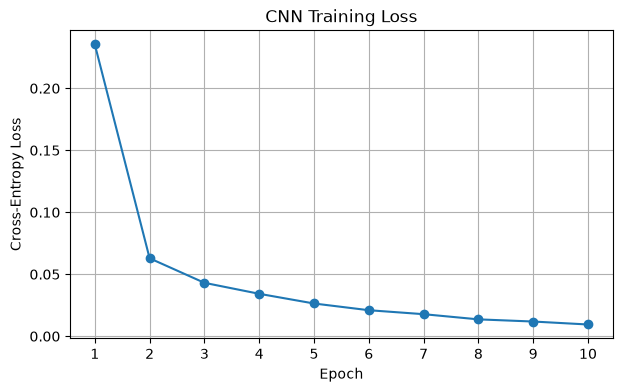

In [21]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o"
)

plt.title("CNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.show()

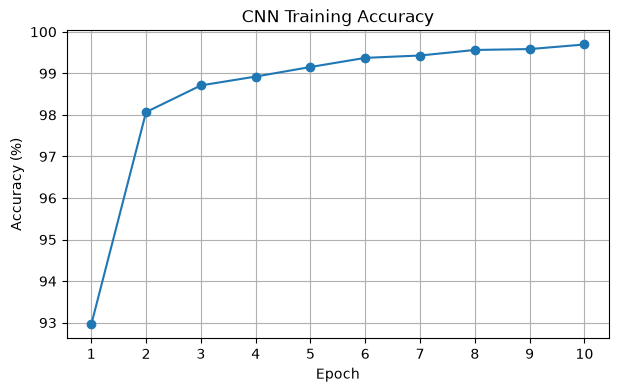

In [22]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, epochs + 1),
    train_accuracies,
    marker="o"
)

plt.title("CNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.show()

In [23]:
torch.save(
    model.state_dict(),
    "digit_cnn_trained.pth"
)

print("Trained model saved successfully!")

Trained model saved successfully!


In [24]:
loaded_model=DigitCNN().to(device)
loaded_model.load_state_dict(
    torch.load(
         "digit_cnn_trained.pth",
        map_location=device,
        weights_only=True
    )
)
loaded_model.eval()

print("Saved model loaded successfully!")

Saved model loaded successfully!


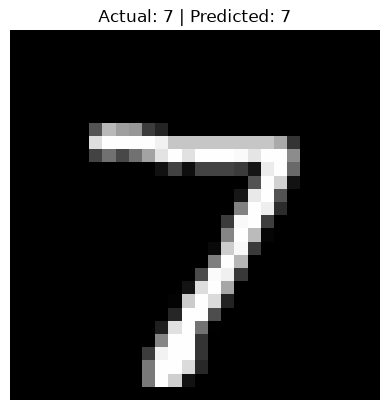

Actual digit: 7
Predicted digit: 7
Model confidence: 100.00%


In [30]:
image, actual_label = test_dataset[0]

loaded_model.eval()

with torch.no_grad():
    input_image = image.unsqueeze(0).to(device)

    logits = loaded_model(input_image)

    predicted_label = logits.argmax(dim=1).item()

    probabilities = torch.softmax(logits, dim=1)
    confidence = probabilities[0, predicted_label].item() * 100

plt.imshow(image.squeeze(0), cmap="gray")
plt.title(
    f"Actual: {actual_label} | "
    f"Predicted: {predicted_label}"
)
plt.axis("off")
plt.show()

print("Actual digit:", actual_label)
print("Predicted digit:", predicted_label)
print(f"Model confidence: {confidence:.2f}%")